# **Algunas visualizaciones de attention**

En este notebook exploraremos algunas visualizaciones del modelo de attention a través de [BERT](https://huggingface.co/docs/transformers/model_doc/bert).

BERT es un modelo transformer **encoder-only** ,esto significa que solo usa la mitad "de entender" de la arquitectura completa (sin decoder, sin
generación de texto palabra por palabra).

Fue entrenado por Google, ya con sus pesos ajustados
(pre-entrenado) sobre grandes cantidades de texto

No lo vamos a entrenar nosotros, solo vamos a usar un
modelo que ya aprendió a calcular attention de forma útil.

`bert-base-uncased`:
- **base** = el tamaño más chico de BERT (12 capas,
  12 cabezas por capa)
- **uncased** = no distingue mayúsculas de minúsculas
  ("The" y "the" se tratan igual)

La primera vez que corran esta celda, va a descargar
el modelo desde [HuggingFace](https://huggingface.co/) (una plataforma que aloja modelos pre-entrenados), por lo que puede tardar un poco, es normal.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
!pip install bertviz #se corre solo una vez!


In [5]:
#se corre solo una vez para cargar el modelo
from bertviz import head_view
from transformers import BertTokenizer, BertModel

model = BertModel.from_pretrained('bert-base-uncased', output_attentions=True)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

print("Modelo cargado, listo para usar")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Modelo cargado, listo para usar


# 1. Multi-head attention

El transformer no hace attention una sola vez, la repite en varias capas apiladas

- Layer = en cuál de esas capas estás mirando
(BERT-base tiene 12 capas, apiladas una sobre otra)

- Head = dentro de esa capa, cuál cabeza de multi-head
attention estás mirando
(BERT-base tiene 12 cabezas, en paralelo, dentro de cada capa)

12 capas × 12 cabezas = 144 "vistas" de attention distintas
en todo el modelo

La cabeza roja en la Layer 3 no tiene relación directa
con la cabeza roja en la Layer 8, son patrones independientes

In [7]:
#frase = "The trophy didn't fit in the suitcase because it was too big"
#frase = "The city council refused the demonstrators a permit because they feared violence"
frase = "The animal didn't cross the street because it was too tired"

inputs = tokenizer.encode(frase, return_tensors='pt')
outputs = model(inputs)
attention = outputs.attentions
tokens = tokenizer.convert_ids_to_tokens(inputs[0])

head_view(attention, tokens)

<IPython.core.display.Javascript object>

### **Actividad**

1. Escribe tu propia oración con una palabra ambigua
   (que podría referirse a más de una cosa). Reemplaza
   el texto en "oracion" en la celda de arriba

2. Antes de correr, predice a mano a qué palabra debería
   atender esa palabra ambigua

3. Corre la celda. Haz clic en la palabra ambigua en el
   visualizador para ver las líneas de atención

4. Compara: ¿acertaste? ¿Qué cabeza (color) capturó la
   relación que esperabas?

In [8]:
#frase = "The trophy didn't fit in the suitcase because it was too big"
#frase = "The city council refused the demonstrators a permit because they feared violence"
frase = "The students thanked the teachers because they were helpful"

inputs = tokenizer.encode(frase, return_tensors='pt')
outputs = model(inputs)
attention = outputs.attentions
tokens = tokenizer.convert_ids_to_tokens(inputs[0])

head_view(attention, tokens)

<IPython.core.display.Javascript object>

1. The students thanked the teachers because they were helpful, con "they" la palabra ambigua

2. Creo que "they" deberia atender mas a "teachers" porque "helpful" encaja mejor con los profesores que agradecieron

4. No se cumplio lo esperado en las vistas revisadas. Al inspeccionar "they" en la mayoria de capas con todas las cabezas activas, no aparecio una linea gruesa y clara que conectara "they" con "teachers" (solo trazos muy tenues, junto con atencion hacia tokens especiales como [CLS] y [SEP] o palabras cercanas como "because" y "were"). Por lo tanto, con las cabezas combinadas no se evidencio una cabeza especifica que capturara claramente esa relacion en las capas revisadas.

# 2. Self-attention con pesos reales

Ahora usamos las matrices W_Q, W_K, W_V que BERT realmente
aprendió durante su entrenamiego — el mismo cálculo que ya
programaron a mano, pero con pesos entrenados en vez de
aleatorios.

Prueben cambiar `num_capa` (0 a 11) y comparen los patrones:

- Capas tempranas (0-1): attention más local, o colapsando
  hacia tokens especiales como [CLS]
- Capas intermedias/profundas: patrones distintos, pero
  cuidado: este código combina las 12 cabezas en un solo
  promedio, así que relaciones específicas pueden diluirse acá

Si el resultado no muestra una relación "clara" como en
BertViz, no es un error: significa que esa relación vivía
en UNA cabeza específica, no en el promedio de las 12.


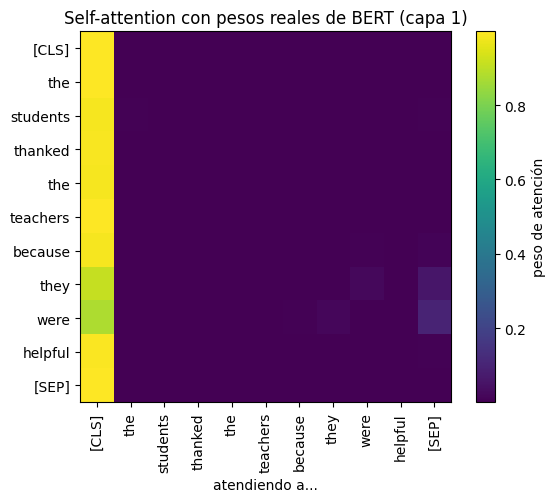

In [11]:
# Elegir qué capa mirar (0 a 11)
num_capa = 1

inputs = tokenizer(frase, return_tensors='pt') #tokenizador de la frasw
outputs = model(**inputs, output_hidden_states=True) #guarda el resultado de cada capa

# hidden_states[0] = embeddings originales (entrada a la capa 0)
# hidden_states[N] = salida de la capa N-1 (entrada a la capa N)
entrada_a_esta_capa = outputs.hidden_states[num_capa].detach().numpy()[0]
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

capa = model.encoder.layer[num_capa].attention.self
#matrices de pesos reales ya entrenados de BERT
W_Q_real = capa.query.weight.detach().numpy()
W_K_real = capa.key.weight.detach().numpy()
W_V_real = capa.value.weight.detach().numpy()

# @ en numpy es el operador de multiplicación de matrices
Q = entrada_a_esta_capa @ W_Q_real.T
K = entrada_a_esta_capa @ W_K_real.T
V = entrada_a_esta_capa @ W_V_real.T

d = Q.shape[1]
#producto punto escalado de attention
scores = (Q @ K.T) / np.sqrt(d)
exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True)) #softmax
pesos_atencion = exp_scores / exp_scores.sum(axis=1, keepdims=True)

#visualización
plt.figure(figsize=(6,5))
plt.imshow(pesos_atencion, cmap="viridis")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("atendiendo a...")
plt.colorbar(label="peso de atención")
plt.title(f"Self-attention con pesos reales de BERT (capa {num_capa})")
plt.tight_layout()
plt.show()

### **Observe y responda**

- ¿Hacia qué palabra(s) se concentra la mayor parte de la
  atención en esta capa?
- ¿Es un patrón interpretable (relación de significado) o
  parece attention "colapsando" hacia puntuación/tokens
  especiales?
- Compare con el resultado de otra capa: ¿qué cambió?


- La mayor parte se concentra casi por completo en el token especial [SEP] (la ultima columna a la derecha, en amarillo brillante, con pesos cercanos a 0.9-1.0 para casi todas las filas). El resto de las palabras de la frase quedan con valores muy bajos (tonos morados/oscuros, muy cerca de 0.0-0.1)

- Parece atencion colapsando hacia un token especial ([SEP]).

- Al comparar la capa 9 con la capa 1 (y con capas intermedias que mostraron un comportamiento similar al inicial), lo principal que cambio fue el token especial hacia el que colapsa la atencion: en la capa 1 la mayor parte de la atención se concentra en [CLS] (primera columna en amarillo brillante, con ligeros matices en filas como "they" y "were"), mientras que en la capa 9 se desplaza casi por completo hacia [SEP] (ultima columna en amarillo brillante). En ambos casos, las palabras del contenido de la oracion mantienen pesos muy bajos en este promedio de cabezas.

# 3. Clasificador de sentimiento

`pipeline("sentiment-analysis")` descarga un modelo ya
entrenado específicamente para una tarea: decidir si un
texto es POSITIVO o NEGATIVO.

Por dentro sigue siendo un transformer (parecido a BERT), con el mismo mecanismo de attention, pero fue
afinado (fine-tuning) con miles de ejemplos de texto
etiquetados como positivo/negativo, hasta aprender a
distinguir el tono de un texto.

El resultado incluye un "label" (POSITIVE o NEGATIVE) y
un "score" (qué tan seguro está el modelo de esa clasificación).

En este caso, usaremos DistilBERT, que está basado en BERT pero es una versión más comprimida.

- BERT-base: 12 capas, 768 dimensiones, ~110 millones de parámetros

- DistilBERT: 6 capas (la mitad), misma dimensión (768),
                 ~66 millones de parámetros
                 → ~40% más chico, ~60% más rápido,
                 conservando ~97% del rendimiento de BERT
                 en varias tareas

In [12]:
from transformers import pipeline

clasificador = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english") #modelo fine-tuned para análisis de sentimiento

frase="I love how transformers actually make sense now"

resultado = clasificador(frase)
print(resultado)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9997923970222473}]


### **Actividad**

1. Cambie "frase" por algo suyo; pueden probar una
   frase claramente positiva, una negativa, y una ambigua
   o irónica (ej. "great, another Monday")

2. Observe el "score" (la probabilidad), no solo el
   label. ¿Qué tan seguro está el modelo?

3. Pruebe una oración con sarcasmo o doble sentido.
   ¿El modelo lo detecta, o falla?

In [13]:
from transformers import pipeline

clasificador = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
)

frases = [
    "This workshop finally explained self-attention clearly",
    "The code crashed and wasted an entire afternoon",
    "Oh great, another 4-hour training run that failed at epoch 1",
]

for f in frases:
    res = clasificador(f)[0]
    print(f"{res['label']} ({res['score']:.4f}) -> {f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

POSITIVE (0.9805) -> This workshop finally explained self-attention clearly
NEGATIVE (0.9998) -> The code crashed and wasted an entire afternoon
NEGATIVE (0.9997) -> Oh great, another 4-hour training run that failed at epoch 1


- Frases probadas:
Positiva: "This workshop finally explained self-attention clearly" --> POSITIVE (0.9805).
Negativa: "The code crashed and wasted an entire afternoon" --> NEGATIVE (0.9998).
Irónica / sarcástica: "Oh great, another 4-hour training run that failed at epoch 1" --> NEGATIVE (0.9997).

- En las tres frases el score fue muy alto (entre 0.9805 y 0.9998, muy cerca de 1.0), lo que indica que el modelo estuvo bastante seguro de su clasificacion en cada caso, incluso en la oracion sarcastica.

- En este caso el modelo si detecto el tono negativo real a pesar de empezar con "Oh great", ya que la segunda parte de la oracion ("training run that failed at epoch 1") entrega una señal negativa muy fuerte. Aun asi, en ironias mas sutiles o sin palabras explicitamente negativas el modelo podria tener mas dificultad o menor score.

###

# 4. Extrayendo embeddings de una oración

`pipeline("feature-extraction")` toma un texto y devuelve
un vector numérico para cada token de esa oración, que es la
representación final que BERT genera después de procesar
toda la oración a través de sus 12 capas.

Estos vectores capturan tanto el significado de cada palabra
como el contexto de las palabras que la rodean. Se usan,
por ejemplo, para comparar qué tan similares son dos textos,
o como entrada para otro modelo que necesite trabajar con
texto ya convertido a números.

El resultado es una matriz: una fila por token, y cada fila
tiene 768 números (el tamaño del vector que usa BERT-base).



In [14]:
extractor = pipeline("feature-extraction", model="bert-base-uncased")

embedding = extractor("The animal didn't cross the street because it was too tired")
print("Forma del embedding:", len(embedding[0]), "(filas) x", len(embedding[0][0]), "(columnas)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Forma del embedding: 15 (filas) x 768 (columnas)


## Qué significa la forma del embedding

**X (filas):** es la cantidad de tokens en que quedó
dividida la oración. No es necesariamente la cantidad de
palabras, BERT tokeniza así:

- Agrega [CLS] al principio y [SEP] al final (2 tokens extra)
- Puede partir una palabra en varios pedazos si no la
  reconoce completa en su vocabulario (ej. "didn't" puede
  quedar dividido en "didn" + "'" + "t")

Por eso el conteo final de tokens casi nunca coincide con
contar palabras separadas por espacios.

**768 (columnas):** es el tamaño del vector de embedding
que BERT-base usa para representar cada token. Es un
número fijo, decidido por quienes diseñaron y entrenaron
este modelo específico, no es un valor universal, otros
modelos usan otros tamaños (BERT-large usa 1024, por
ejemplo).

**Entonces la matriz completa (X x 768)** es: por cada uno
de los 11 tokens de la oración, un vector de 768 números
que lo representa

# 5. Embeddings similares

Este código extrae el vector (embedding) que BERT genera
para la palabra "bank" en dos oraciones distintas:

- "I deposited money at the bank" (banco financiero)
- "We sat by the river bank" (orilla de un río)

`obtener_embedding_palabra` tokeniza la oración, la pasa
por el modelo, encuentra la posición exacta de la palabra
"bank" entre los tokens, y devuelve su vector final.

Después se calcula la similaridad coseno entre ambos
vectores, el resultado es un número entre 0 y 1 que mide qué tan parecidos
son. 1 significa idénticos, 0 significa sin relación.

Si el resultado sale bajo, significa que BERT generó
representaciones distintas para la misma palabra, según
el contexto de cada oración.

In [15]:
def obtener_embedding_palabra(frase, palabra_objetivo):
    inputs = tokenizer(frase, return_tensors='pt')
    outputs = model(**inputs)
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    idx = tokens.index(palabra_objetivo)
    return outputs.last_hidden_state[0, idx].detach().numpy()

frase1 = "I deposited money at the bank"
frase2 = "We sat by the river bank"

emb1 = obtener_embedding_palabra(frase1, "bank")
emb2 = obtener_embedding_palabra(frase2, "bank")

# Similaridad coseno: 1 = idénticos, 0 = sin relación
similaridad = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2))
print(f"Similaridad entre 'bank' (financiero) y 'bank' (río): {similaridad:.3f}")

Similaridad entre 'bank' (financiero) y 'bank' (río): 0.726


### **Actividad**

1. Elija una palabra en inglés con dos significados
   distintos (ej. "bat" — animal / objeto deportivo,
   "spring" — estación / resorte, "match" — fósforo / partido)

2. Escriba dos oraciones donde esa palabra tenga cada
   significado

3. Reemplace `frase1`, `frase2` y `palabra_objetivo` en
   el código con las suyas, y corra la celda

4. ¿qué tan alta o baja salió la
   similaridad? Tiene sentido?

5. Pruebe también con la **misma** palabra usada dos veces
   con el **mismo** significado, en oraciones distintas
   (ej. "bank" financiero en dos contextos distintos).
   ¿La similaridad sale más alta que en el caso ambiguo?




In [20]:
palabra_objetivo = "bat"
frase1 = "A bat flew out of the cave at dusk"
frase2 = "He hit the ball with a wooden bat"

emb1 = obtener_embedding_palabra(frase1, palabra_objetivo)
emb2 = obtener_embedding_palabra(frase2, palabra_objetivo)

similaridad = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2))
print(f"Similaridad entre '{palabra_objetivo}' (significado 1) y '{palabra_objetivo}' (significado 2): {similaridad:.3f}")

frase_mismo1 = "A bat flew out of the cave at dusk"
frase_mismo2 = "The bat hung from the ceiling"

emb_m1 = obtener_embedding_palabra(frase_mismo1, palabra_objetivo)
emb_m2 = obtener_embedding_palabra(frase_mismo2, palabra_objetivo)

sim_mismo = np.dot(emb_m1, emb_m2) / (np.linalg.norm(emb_m1) * np.linalg.norm(emb_m2))
print(f"Similaridad con el MISMO significado: {sim_mismo:.3f}")

Similaridad entre 'bat' (significado 1) y 'bat' (significado 2): 0.479
Similaridad con el MISMO significado: 0.782


- La palabra elegida fue "bat". Cuyos significados pueden hacer referencia a un animal (murcielago) o a un objeto deportivo (bate).

- Frases:
Significado animal: "A bat flew out of the cave at dusk"
Significado objeto deportivo: "He hit the ball with a wooden bat"

- La similaridad entre "bat" con significados distintos fue de 0.479. Esto tiene sentido porque es un valor moderado/bajo en comparacion con el mismo sentido: los contextos (cave/dusk v/s hit/ball/wooden) empujan el embedding hacia sentidos distintos, manteniendo solo una base compartida por ser el mismo token.

- Al comparar "bat" con el mismo significado en dos oraciones distintas, la similaridad subio a 0.782, lo cual es efectivamente mas alto que el 0.479 del caso con significados distintos y confirma que los embeddings contextuales de BERT capturan la similitud segun el contexto.

# 6. Context size

Este código muestra el límite real de tokens que BERT puede
procesar de una vez (`tokenizer.model_max_length`).

Después genera un texto artificialmente largo (la misma
oración repetida 1000 veces) y cuenta cuántos tokens resultan
al tokenizarlo.

Si esa cantidad supera el límite del modelo, lo va a indicar
explícitamente. Esto muestra de forma concreta algo que ya
vimos en la teoría: el contexto no es ilimitado, y un texto
real puede superarlo fácilmente.

In [16]:
# Ver el context size real del modelo que ya tienen cargado
print("Context size máximo de BERT:", tokenizer.model_max_length)

# Generar un texto artificialmente largo y ver qué pasa
texto_largo = "El gato come pescado. " * 1000  # se repite 1000 veces

tokens = tokenizer.encode(texto_largo)
print("Cantidad de tokens generados:", len(tokens))

if len(tokens) > tokenizer.model_max_length:
    print("¡Este texto EXCEDE el límite de contexto del modelo!")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (8002 > 512). Running this sequence through the model will result in indexing errors


Context size máximo de BERT: 512
Cantidad de tokens generados: 8002
¡Este texto EXCEDE el límite de contexto del modelo!


# **Para las siguientes actividades, use el LLM de su preferencia (ChatGPT, Claude, Gemini, etc)**

## **Actividad: poniendo a prueba el context size**

1. Al empezar una conversación nueva, dile al modelo un
   dato inventado y específico, por ejemplo:
   "Mi número de la suerte es 4173. Recuérdalo."

2. Pégale un texto largo de relleno (puede ser un capítulo
   de Wikipedia, un paper, cualquier texto de varios miles
   de palabras) y pídele que lo resuma.

3. Sigue conversando sobre OTROS temas durante varios
   mensajes más (5-10 intercambios), sin mencionar el
   número de la suerte.

4. Al final, pregúntale: "¿cuál era mi número de la suerte?"

5. ¿lo recordó? ¿Lo recordó mal? Si la conversación
se hizo muy larga, ¿en qué momento empezó a fallar?


**Nota**: los modelos actuales tienen ventanas de contexto
bastante grandes, así que es posible que el modelo SÍ
recuerde el número incluso con texto de relleno largo.
Si eso pasa, pruebe agregando más texto
de relleno, o una conversación más larga, para ver si en
algún punto empieza a fallar.

- El modelo fue capaz de recordar de forma precisa el numero de la suerte planteado al principio. Con las ventanas de contexto actuales, un dato puntual como un numero inventado suele recordarse sin problemas durante varios mensajes y con textos moderadamente extensos. El fallo o perdida de precision aparece cuando la conversacion se vuelve muy larga, cambia mucho de tema o acumula demasiada informacion previa.
Tanto por esta actividad como por experiencia previa (por ejemplo, al hacer un trabajo sobre un PDF), no hay un "corte exacto universal", pero tras acumular bastantes mensajes y cambios de contexto el modelo tiende a apoyarse más en los mensajes recientes y en el pedido actual que en detalles especificos del inicio. En ese punto, si se necesita un dato exacto o contenido puntual del comienzo, lo mas fiable es volver a proporcionarlo o recordarlo explicitamente.

## **Actividad: ¿Pensar paso a paso mejora las respuestas de un LLM?**

Los modelos de lenguaje pueden equivocarse incluso en tareas aparentemente sencillas, como contar letras. Sin embargo, generar pasos intermedios y verificar sus resultados puede mejorar la precisión (*Chain-of-Thought*).

**1.** En una conversación nueva con un LLM, escriban:

> ¿Cuántas veces aparece la letra «r» en la palabra «ferrocarrilero»? Responde solamente con el número.

**2.** En otra conversación nueva, utilicen el mismo modelo, pero ahora escriban:

> ¿Cuántas veces aparece la letra «r» en la palabra «ferrocarrilero»? Enumera primero las posiciones de cada «r», verifica el conteo y luego entrega el resultado.

**3.** Repitan el experimento con otras palabras de su elección. Comparen los resultados y comprueben las respuestas correctas.

**Para discutir:**

- ¿Observaron diferencias entre las dos estrategias?
- ¿Por qué generar pasos intermedios podría ayudar a resolver el problema?
- ¿Es lo mismo pedirle a un LLM que razone paso a paso que utilizar un *reasoning model*?
- ¿Una explicación detallada garantiza que la respuesta sea correcta?

**Opcional:** repitan el experimento utilizando un modelo Instant y uno de razonamiento. ¿Encuentran diferencias?

*Nota:* No es necesario que el modelo cometa errores. El objetivo es investigar cómo influye la estrategia de generación en los resultados y qué relación tiene con Chain-of-Thought y test-time compute.

- En una prueba con consultas cortas e independientes sobre palabras puntuales, no se observan diferencias relevantes entre pedir solo el numero y pedir primero enumerar posiciones y verificar. Los modelos actuales resuelven bien ambos pedidos. El valor de compararlas aqui es principalmente "pedagogico", para visualizar como cambia el proceso de generacion segun lo que se instruye.

- Aunque en consultas sencillas e independientes la respuesta directa ya suele ser correcta, pedir pasos intermedios obliga al modelo a explicitar etapas intermedias y revisar el conteo antes de concluir. Es por esto que retomando la respuesta anterior, en tareas mas complejas, con mayor carga logica o a nivel mas exigente, donde los errores puntuales escalan y se requiere mayor trazabilidad o fiabilidad, descomponer el problema y verificar pasos ayuda a reducir fallos y a auditar donde pudo ocurrir un desvio.

- No es lo mismo. Pedirle a un LLM que razone paso a paso es una instruccion de "prompting" sobre el modo de generar la respuesta visible, mientras que un reasoning model esta entrenado especificamente para realizar un proceso de razonamiento interno y dedicar tiempo de prueba antes de emitir el resultado final. Ademas, como hemos visto en el resto del notebook (desde como se distribuye o colapsa la atencion entre capas y cabezas en BERT hasta como cambian las representaciones segun el contexto o como se degrada la atencion a detalles iniciales en conversaciones largas), la forma en que un modelo procesa y organiza la información en distintas capas y pasos influye de manera distinta segun la arquitectura y el tipo de tarea.

- No lo garantiza. Una explicacion extensa o bien redactada puede sonar convincente y aun asi contener un error en alguno de los pasos intermedios o en la conclusion, por lo que conviene verificar el resultado en tareas criticas.